[Sommaire](00_sommaire.ipynb) · [Thème 1 — Listes, sets, dicts](theme1_listes_sets_dicts.ipynb) ➡

# Thème 0 — Mesurer la vitesse d'un algorithme : la notation O(…)

**Dans ce notebook, tu vas apprendre :**
- ce que veulent dire O(1), O(n), O(n²) et O(n log n) ;
- reconnaître la complexité d'un code en le lisant (y compris les boucles cachées) ;
- lire les contraintes d'un énoncé pour savoir quelle complexité viser.

**Prérequis :** aucun

Tout au long de cette série, on dira qu'une solution est « en **O(n)** » ou « en **O(n²)** ». C'est le critère qui fait passer ou échouer une solution dans un test chronométré : il faut donc le comprendre avant tout le reste.

## Le problème de départ
Tu as écrit une solution **correcte** : elle donne la bonne réponse sur les exemples de l'énoncé. Pourtant le correcteur automatique répond **« Time Limit Exceeded »** (temps dépassé).
Pourquoi ? Parce que les tests cachés utilisent des listes de 100 000 éléments, et ta solution fait beaucoup trop d'opérations.

## Le concept : compter les opérations, pas les secondes
Le temps en secondes dépend de l'ordinateur. Ce qui n'en dépend pas, c'est le **nombre d'opérations** que fait l'algorithme **en fonction de la taille de l'entrée**. Cette taille, on l'appelle `n` (par exemple : le nombre d'éléments de la liste).

La notation **O(…)** (on dit « grand O ») répond à une seule question :

> **Si l'entrée devient 10 fois plus grande, combien de fois plus de travail faut-il ?**

### Image mentale : une soirée avec beaucoup d'invités
- **O(1) — temps constant.** Tu donnes ton ticket « n°42 » au vestiaire. On va directement au crochet 42. Qu'il y ait 10 ou 10 000 manteaux, ça prend le même temps.
- **O(n) — temps linéaire.** Tu cherches « Alice » parmi les invités, sans liste. Tu demandes à chacun, un par un. 10× plus d'invités → 10× plus de temps.
- **O(n²) — temps quadratique.** Tu veux savoir si deux invités ont le même prénom, en **comparant chaque invité avec chacun des autres**. Avec 1 000 invités, ça fait environ 1 000 × 1 000 = **1 million** de comparaisons. 10× plus d'invités → **100×** plus de temps.

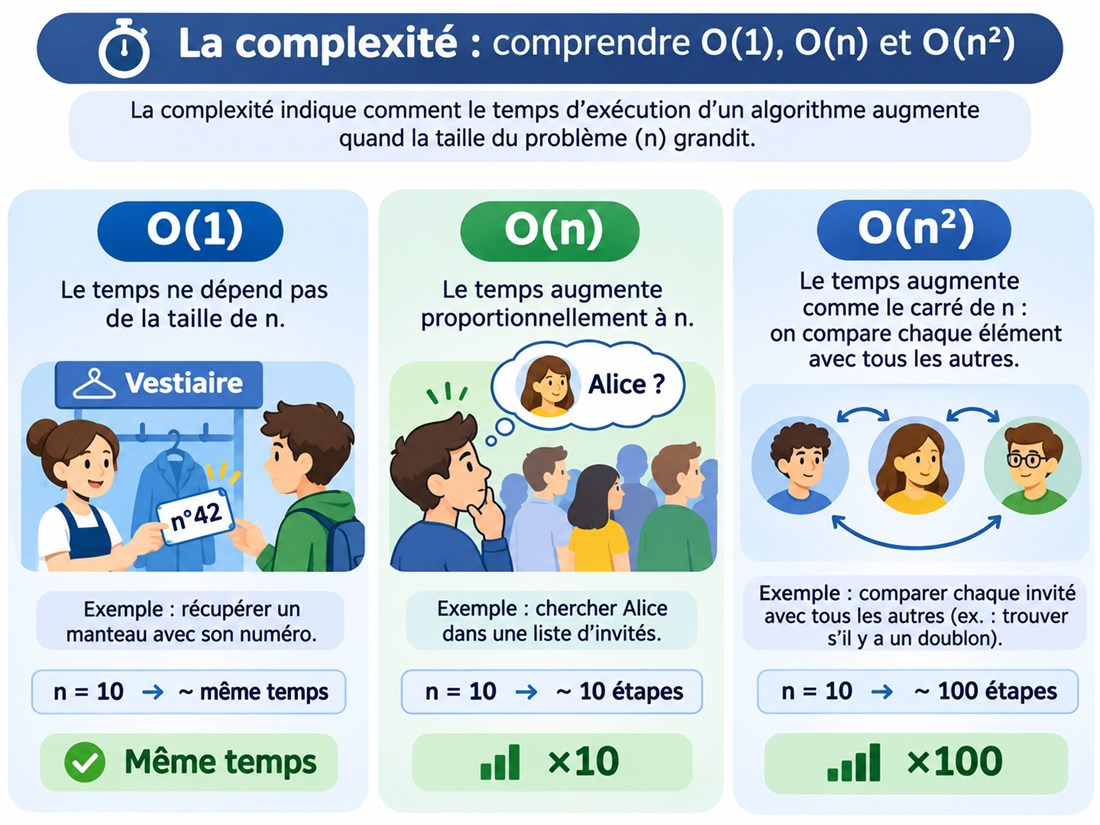

Les trois images mentales en une figure. Les badges du bas répondent à la question du début : si `n` est multiplié par 10, le travail reste le même (O(1)), est multiplié par 10 (O(n)), ou par 100 (O(n²)).

### Reconnaître la complexité en lisant le code
| Ce que tu vois dans le code | Complexité |
|---|---|
| Une opération simple : `a + b`, `liste[i]`, `x in un_set` | O(1) |
| Une boucle `for` sur les `n` éléments | O(n) |
| Deux boucles `for` **imbriquées** sur les `n` éléments | O(n²) |
| `x in une_liste`, `liste.index(x)`, `liste.count(x)`, `min(liste)`, `sum(liste)` | O(n) — **c'est une boucle cachée !** |
| `sorted(liste)` ou `liste.sort()` | O(n log n) — à peine plus que O(n) |

Le piège le plus fréquent est l'avant-dernière ligne : `if x in liste:` placé **dans** une boucle a l'air innocent, mais c'est une boucle dans une boucle → O(n²).

(`log n` est un nombre très petit : pour n = 1 000 000, log₂ n ≈ 20. Donc O(n log n) reste très rapide.)

### Pourquoi c'est décisif
Ordre de grandeur à retenir : Python fait environ **10 millions d'opérations simples par seconde**.

| n | Algorithme O(n) | Algorithme O(n²) |
|---|---|---|
| 1 000 | 1 000 opérations → instantané | 1 000 000 → ~0,1 s |
| 100 000 | 100 000 opérations → instantané | 10 000 000 000 → **~17 minutes** |

### Lire les contraintes de l'énoncé
Les énoncés donnent souvent la taille maximale, par exemple `1 ≤ n ≤ 10^5`. C'est un **indice** sur la solution attendue :
- `n ≤ 1 000` → une solution O(n²) passe.
- `n ≤ 100 000` (ou plus) → il faut viser O(n) ou O(n log n).

## On manipule
Compte les opérations de deux fonctions. Observe ce qui se passe quand `n` est multiplié par 10.

In [ ]:
def operations_une_boucle(n):
    operations = 0
    for i in range(n):
        operations += 1            # une opération par élément
    return operations

def operations_deux_boucles(n):
    operations = 0
    for i in range(n):
        for j in range(n):         # pour CHAQUE i, on refait n tours complets
            operations += 1
    return operations

for n in [10, 100, 1000]:
    print(f"n = {n:>5} | une boucle : {operations_une_boucle(n):>9} | deux boucles : {operations_deux_boucles(n):>9}")

Quand `n` est multiplié par 10 : une boucle → **×10** opérations ; deux boucles imbriquées → **×100**.

Maintenant, mesurons pour de vrai la différence entre chercher dans une **liste** et chercher dans un **set** (le set est expliqué au thème 1 — retiens juste le résultat pour l'instant).

In [ ]:
import time

n = 100_000
nombres_liste = list(range(n))
nombres_set = set(nombres_liste)
a_chercher = range(n, n + 1000)    # 1 000 valeurs absentes : le pire cas pour la liste

debut = time.perf_counter()
for x in a_chercher:
    x in nombres_liste             # Python compare x à chaque case, une par une
temps_liste = time.perf_counter() - debut

debut = time.perf_counter()
for x in a_chercher:
    x in nombres_set               # Python va directement « au bon casier »
temps_set = time.perf_counter() - debut

print(f"1 000 recherches dans une liste : {temps_liste:.4f} s")
print(f"1 000 recherches dans un set    : {temps_set:.6f} s")
print(f"→ le set est environ {temps_liste / temps_set:.0f} fois plus rapide")

## Mini-quiz : quelle est la complexité de chaque fonction ?
```python
def a(liste):
    return liste[0] + liste[-1]

def b(liste):
    total = 0
    for x in liste:
        total += x
    return total

def c(liste):
    resultat = []
    for x in liste:
        if x not in resultat:
            resultat.append(x)
    return resultat
```

<details>
<summary><b>Réponses</b></summary>

- `a` : **O(1)** — deux accès par indice, quelle que soit la taille de la liste.
- `b` : **O(n)** — une boucle sur les n éléments.
- `c` : **O(n²)** — une seule boucle visible, mais `x not in resultat` parcourt la liste `resultat` à chaque tour : c'est une boucle cachée. Avec un `set` pour `resultat`, on reviendrait à O(n) (voir thème 1).

</details>

## À retenir
- O(…) indique **comment le travail grandit** quand l'entrée grandit.
- Une boucle dans une boucle = O(n²). Attention aux boucles cachées (`in` sur une liste).
- Lis les contraintes **avant** de coder : elles disent quelle complexité est attendue.

---

**Suite :** [Thème 1 — Listes, sets et dictionnaires](theme1_listes_sets_dicts.ipynb) ➡ · [Retour au sommaire](00_sommaire.ipynb)